# CLUSTER ANALYSIS

In [1]:
# importing the required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import random

random.seed(123)

### K-Means

Let’s look into one of the most common clustering algorithms: K-Means in detail. Let’s see a simple example of how K-Means clustering can be used to segregate the dataset.

In this example, we'll use the `make_blobs` the command to generate isotropic gaussian blobs which can be used for clustering.
We specify the number of samples to be generated to be 100 and the number of centers to be 5.

In [2]:
# number of clusters. make a variable as we may want to change it later
k = 8

In [3]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=100, n_features=2, centers=k, random_state=555)
X, y


(array([[ -4.89235808,  -8.99002917],
        [  4.33259339,   1.35264321],
        [ -4.8702491 ,   6.648911  ],
        [ -7.52367909,   6.84130506],
        [  7.90936956,  -2.40378659],
        [  7.78274795,   2.7330323 ],
        [  2.45391714,   1.16736983],
        [  9.53899469,  -3.32684212],
        [  6.68120951,   3.94863808],
        [  3.19441517,  -0.17098129],
        [  2.14013922,  -5.64983329],
        [  1.3712372 ,   0.80197827],
        [  9.33601659,   3.07941732],
        [  4.29574569,  -8.04511916],
        [ -7.14907522,   4.6815568 ],
        [  8.26210456,   3.59966536],
        [ -7.26437377,   5.1466675 ],
        [  6.1317264 , -10.38077172],
        [  9.03181561,  -3.82587149],
        [  8.26644763,   4.80000778],
        [  8.43669112,  -2.01324913],
        [  2.84236339,  -1.22527498],
        [ -8.1608681 ,   5.50755939],
        [  2.2512047 ,   0.64180859],
        [  9.74335615,  -4.11861423],
        [  2.19555002,   1.04210994],
        [  4

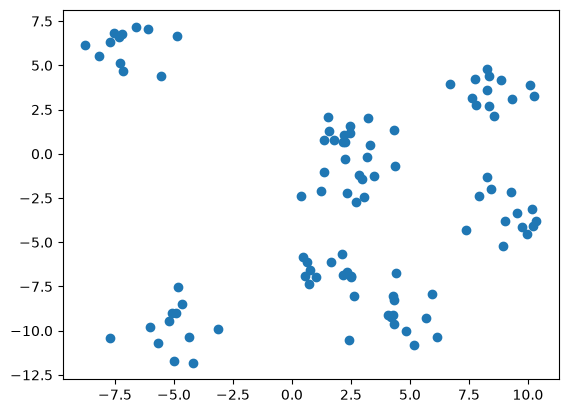

In [4]:
plt.scatter(X[:, 0], X[:, 1])

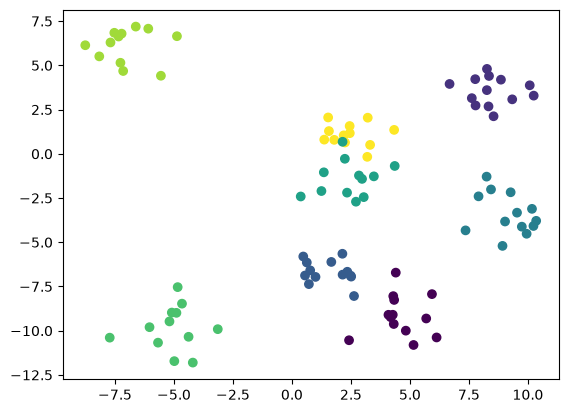

In [5]:
plt.scatter(X[:, 0], X[:, 1], c=y)

As you can see from the above graph, there are 5 clusters that can be created from the dataset.

In [6]:
y

array([5, 7, 6, 6, 3, 1, 7, 3, 1, 7, 2, 7, 1, 0, 6, 1, 6, 0, 3, 1, 3, 4,
       6, 7, 3, 7, 0, 4, 6, 0, 7, 2, 0, 2, 4, 2, 6, 3, 1, 1, 4, 0, 2, 2,
       4, 7, 4, 1, 2, 6, 7, 0, 0, 4, 0, 1, 5, 3, 4, 5, 1, 2, 5, 7, 4, 5,
       5, 1, 2, 3, 0, 6, 1, 2, 4, 3, 5, 6, 4, 6, 0, 5, 7, 3, 5, 3, 0, 2,
       1, 3, 7, 2, 5, 5, 0, 4, 6, 2, 5, 3])

If you look at the value of y, you can see that the points are classified based on their clusters that are predefined by using make_blobs command, we will be using this only for evaluating purpose.

For using K-Means you need to import KMeans from sklearn.cluster library.

In [7]:
from sklearn.cluster import KMeans

For using KMeans, you need to specify a number of clusters as arguments. As we set k=5 at the beginning, we will continue with this number and see the results of step by step algorithm, and compare various methods.


In [8]:
Cluster = KMeans(n_clusters=k, max_iter=200)
Cluster.fit(X)
y_pred = Cluster.predict(X)

After passing the arguments, we fit the model and predict the results. Now let’s visualize our predictions in a scatter plot.

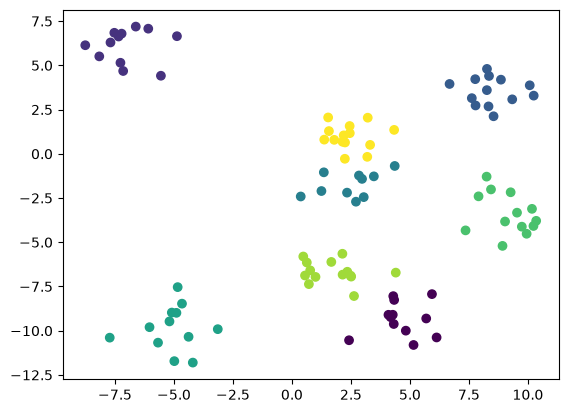

In [9]:
plt.scatter(X[:, 0], X[:, 1], c=y_pred)

You can see that the predicted clusters are mostly the same as the clusters that you saw in the initial scatter plot. Now let’s look into how exactly the K-Means algorithm works.

## Steps Involved
There are 3 important steps in K-Means Clustering.

1. Initialize centroids – This is done by randomly choosing K no of points, the points can be present in the dataset or also random points.
2. Assign Clusters – The clusters are assigned to each point in the dataset by calculating their distance from the centroid and assigning it to the clustersroid with minimum distance.
3. Re-calculate the centroids – Updating the centroid by calculating the centroid of each cluster we have created.
Let’s look into this by an example.

Let's use the same `make_blobs` example we used at the beginning.

We will try to do the clustering without using the KMeans library.

In [10]:
# setting the number of training examples
m=X.shape[0]
n=X.shape[1] 
n_iter=200

We will set the K value to be 5 as before and also initialize the centroids randomly using the `random.randint()` function.

In [11]:
# creating an empty centroid array
centroids=np.array([]).reshape(n,0) 

# creating 5 random centroids
for i in range(k):
    centroids=np.c_[centroids,X[random.randint(0,m-1)]]


In [12]:
centroids

array([[  2.45391714,   2.24411677,   1.3712372 ,  -4.19824115,
          5.69190736,   2.24411677,   4.29574569,   7.90936956],
       [  1.16736983,  -0.28085525,   0.80197827, -11.8015153 ,
         -9.30824347,  -0.28085525,  -8.04511916,  -2.40378659]])

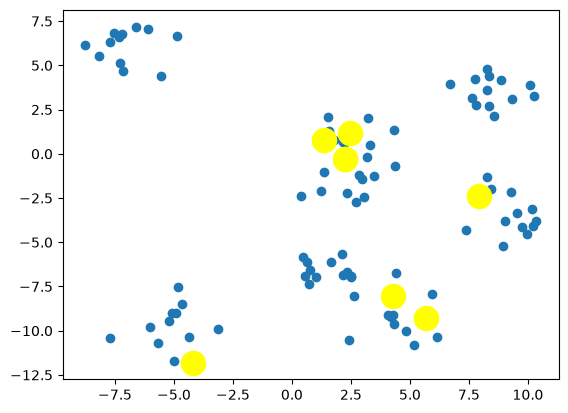

In [13]:
plt.scatter(X[:,0],X[:,1])
plt.scatter(centroids[0,:],centroids[1,:],s=300,c='yellow')
plt.rcParams.update({'figure.figsize':(10,7.5), 'figure.dpi':100})
plt.show()

Next, we'll find the distance between the points. Euclidean distance is most commonly used for finding the similarity.

In [14]:
output={}

# creating an empty array
euclid=np.array([]).reshape(m,0)

# finding distance between for each centroid
for i in range(k):
       dist=np.sum((X-centroids[:,i])**2,axis=1)
       euclid=np.c_[euclid,dist]

# storing the minimum value we have computed
new_clusters=np.argmin(euclid,axis=1)+1


Each row represents a data point <br>
Each column represents the distance to a specific centroid<br>
This allows the algorithm to later find which centroid is closest to each point by taking np.argmin(euclid, axis=1).

In [15]:
euclid

array([[1.57140514e+02, 1.26778984e+02, 1.35116035e+02, 8.38625262e+00,
        1.12127935e+02, 1.26778984e+02, 8.53141058e+01, 2.07262822e+02],
       [3.56375070e+00, 7.03005181e+00, 9.07286237e+00, 2.45807024e+02,
        1.15502239e+02, 7.03005181e+00, 8.83192954e+01, 2.69040927e+01],
       [8.36907046e+01, 9.86358620e+01, 7.31427734e+01, 3.40869825e+02,
        3.66189928e+02, 9.86358620e+01, 2.99929983e+02, 2.45269987e+02],
       [1.31745967e+02, 1.46135004e+02, 1.15593004e+02, 3.58613289e+02,
        4.35459643e+02, 1.46135004e+02, 3.61304428e+02, 3.23650710e+02],
       [4.25151194e+01, 3.66019266e+01, 5.30241032e+01, 2.34911542e+02,
        5.25886633e+01, 3.66019266e+01, 4.48829106e+01, 0.00000000e+00],
       [3.08477368e+01, 3.97599535e+01, 4.48364398e+01, 3.54797174e+02,
        1.49363936e+02, 3.97599535e+01, 1.28327734e+02, 2.64029414e+01],
       [0.00000000e+00, 2.14137208e+00, 1.30570684e+00, 2.12443192e+02,
        1.20223055e+02, 2.14137208e+00, 8.82622858e+01, 4.

In [16]:
new_clusters

array([4, 1, 3, 3, 8, 8, 1, 8, 1, 2, 7, 3, 8, 7, 3, 8, 3, 5, 8, 1, 8, 2,
       3, 1, 8, 1, 7, 2, 3, 7, 3, 7, 7, 7, 2, 7, 3, 8, 8, 8, 2, 7, 7, 7,
       2, 3, 2, 8, 7, 3, 3, 5, 5, 2, 7, 8, 4, 8, 2, 4, 1, 7, 4, 1, 2, 4,
       4, 8, 7, 8, 5, 3, 1, 7, 2, 8, 4, 3, 2, 3, 5, 4, 1, 8, 4, 8, 5, 7,
       1, 8, 1, 7, 4, 4, 7, 1, 3, 7, 4, 8])

Then we regroup the dataset based on the minimum values we got and calculate the new centroid value.

In [17]:
# computing the mean of separated clusters
clusters={}
# creating an empty array
for i in range(k):
    clusters[i+1]=np.array([]).reshape(2,0)

# assigning clusters to the points
for i in range(m):
    clusters[new_clusters[i]]=np.c_[clusters[new_clusters[i]],X[i]]
for i in range(k):
    clusters[i+1]=clusters[i+1].T
# print(clusters)

# computing mean and updating it
for i in range(k):
     centroids[:,i]=np.mean(clusters[i+1],axis=0)
centroids

/home/bob/Documents/GitHub/BootcampAIAccenture2026/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/bob/Documents/GitHub/BootcampAIAccenture2026/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


array([[ 4.69618805,  2.51335697, -4.87164771, -5.06526276,  5.34304822,
                nan,  2.40581118,  9.07680789],
       [ 2.27060324, -1.49716832,  4.89328206, -9.84056939, -9.67369175,
                nan, -7.3928828 , -0.88642452]])

In [18]:
clusters

{1: array([[4.33259339, 1.35264321],
        [2.45391714, 1.16736983],
        [6.68120951, 3.94863808],
        [8.26644763, 4.80000778],
        [2.2512047 , 0.64180859],
        [2.19555002, 1.04210994],
        [7.76897427, 4.21925274],
        [3.3142451 , 0.50498272],
        [8.35240969, 4.40060175],
        [3.21415746, 2.04179417],
        [7.62395619, 3.14669544],
        [2.44804889, 1.57124454],
        [2.14773065, 0.68069332]]),
 2: array([[ 3.19441517, -0.17098129],
        [ 2.84236339, -1.22527498],
        [ 1.35362301, -1.04611941],
        [ 2.24411677, -0.28085525],
        [ 2.71509963, -2.70644893],
        [ 3.04496566, -2.44806531],
        [ 3.47320958, -1.27409942],
        [ 2.97228082, -1.41730123],
        [ 0.37465299, -2.41199651],
        [ 4.35715681, -0.68652225],
        [ 2.33664998, -2.19463993],
        [ 1.25174986, -2.10371533]]),
 3: array([[-4.8702491 ,  6.648911  ],
        [-7.52367909,  6.84130506],
        [ 1.3712372 ,  0.80197827],
     

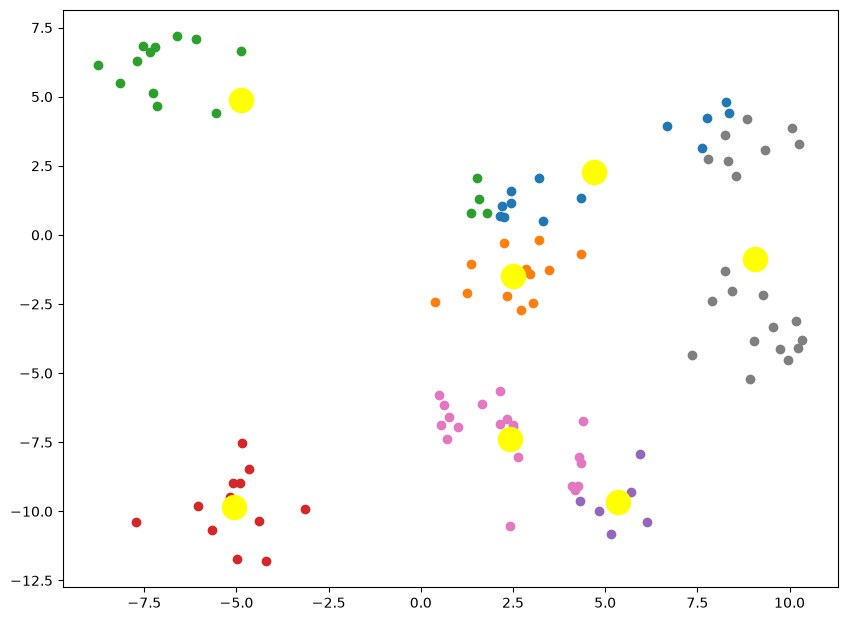

In [19]:
for i in range(k):
    plt.scatter(clusters[i+1][:,0],clusters[i+1][:,1])
plt.scatter(centroids[0,:],centroids[1,:],s=300,c='yellow')
plt.rcParams.update({'figure.figsize':(10,7.5), 'figure.dpi':100})
plt.show()

Then we need to repeat the above 2 steps over and over again until we reach the convergence.

In [20]:
# repeating the above steps again and again
for i in range(n_iter):
      euclid=np.array([]).reshape(m,0)
      for i in range(k):
          dist=np.sum((X-centroids[:,i])**2,axis=1)
          euclid=np.c_[euclid,dist]
      C=np.argmin(euclid,axis=1)+1
      clusters={}
      for i in range(k):
           clusters[i+1]=np.array([]).reshape(2,0)
      for i in range(m):
           clusters[C[i]]=np.c_[clusters[C[i]],X[i]]
      for i in range(k):
           clusters[i+1]=clusters[i+1].T
      for i in range(k):
           centroids[:,i]=np.mean(clusters[i+1],axis=0)
      final=clusters

Let’s plot it.

Text(0.5, 1.0, 'Original Dataset')

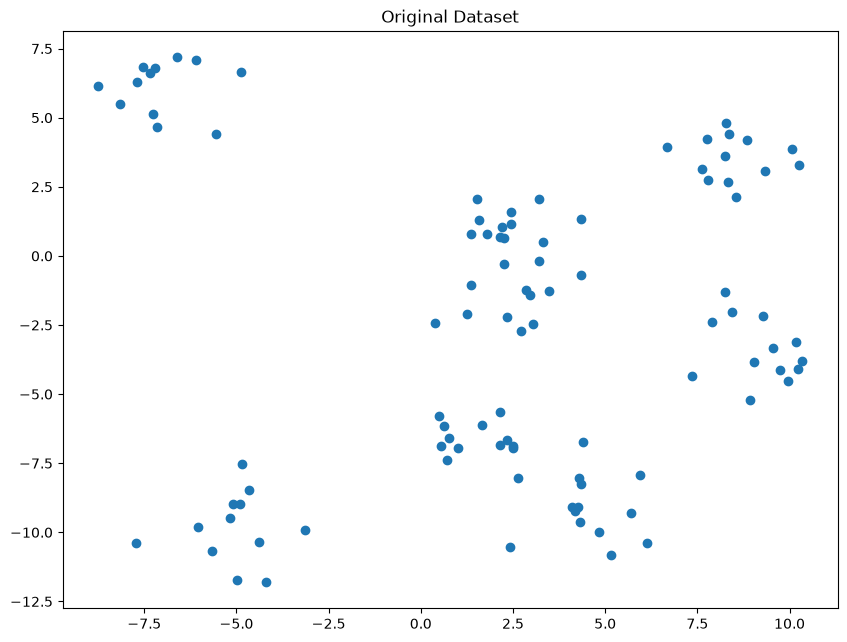

In [21]:
plt.scatter(X[:,0],X[:,1])
plt.title('Original Dataset')

This is the original dataset where it is hard to visually distinguish the clusters

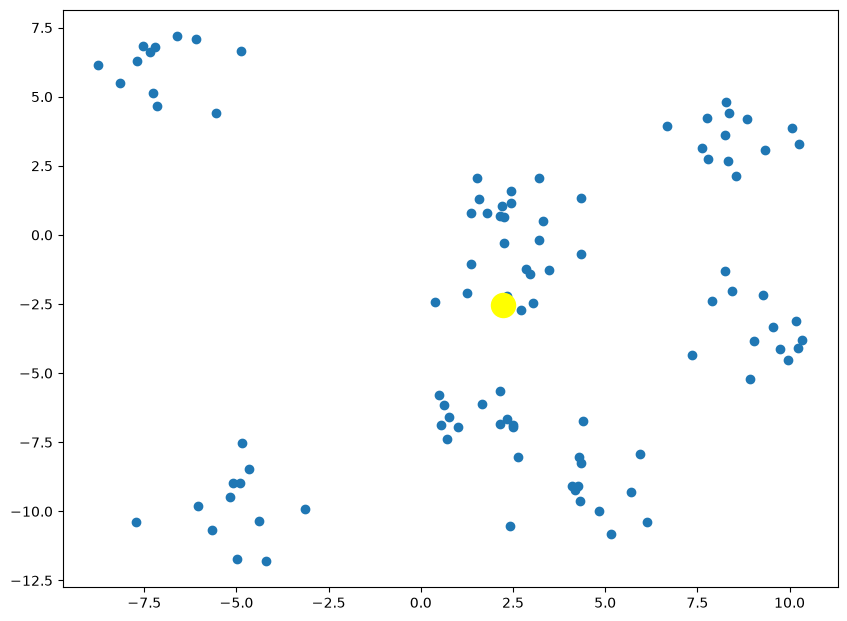

In [22]:
for i in range(k):
    plt.scatter(final[i+1][:,0],final[i+1][:,1])
plt.scatter(centroids[0,:],centroids[1,:],s=300,c='yellow')
plt.show()

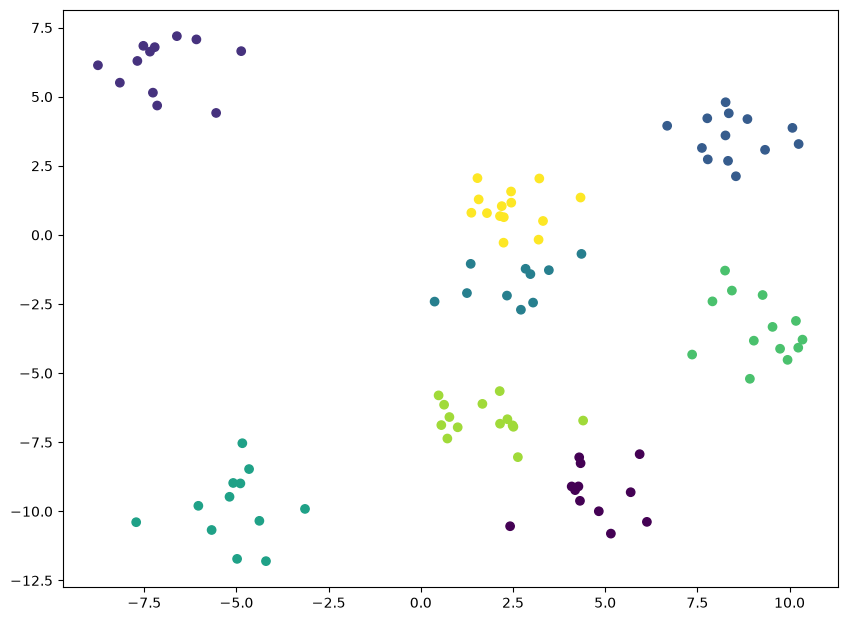

In [23]:
# the plot obtained by built-in KMeans 
plt.scatter(X[:, 0], X[:, 1], c=y_pred)

### Elbow method to find the optimal number of clusters

One of the important steps in K-Means Clustering is to determine the optimal number of clusters we need to give as an input. This can be done by iterating it through a number of n values (clusters) and then finding the optimal n value.

For finding this optimal n, the Elbow Method is used.

You have to plot the loss values vs the n value and find the point where the graph is flattening, this point is considered as the optimal n value.

Let’s look at the example we have seen at first, to see the working of the elbow method.

We will to iterate it through a series of n values ranging from 1-20 and then plot their loss values.

In [24]:
len(X)

100

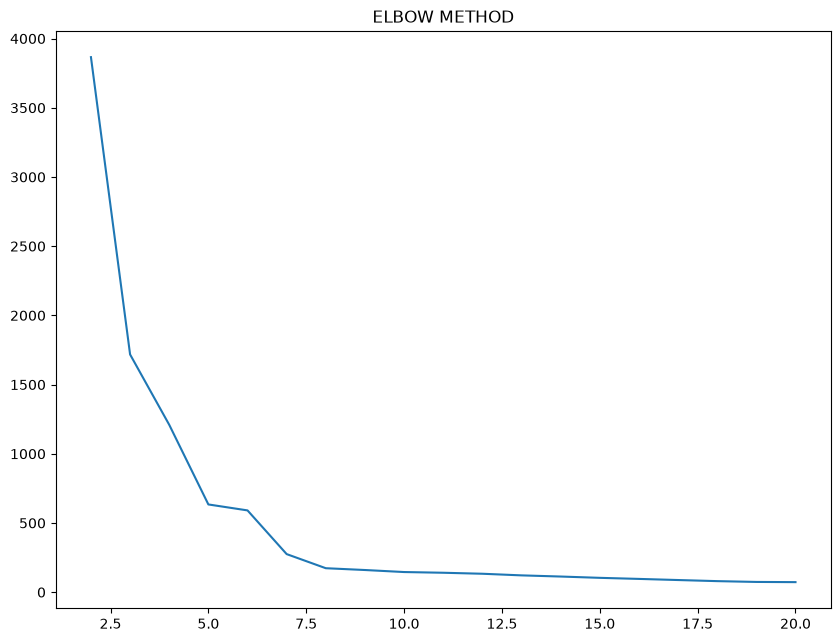

In [25]:
elbow=[]
for i in range(2, 21):  # we don't need 0 and 1
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=555, max_iter=200)
    kmeans.fit(X)
    elbow.append(kmeans.inertia_)

plt.plot(range(2, 21), elbow)
plt.title('ELBOW METHOD')
plt.show()

You can see that the graph starts to flatten after reaching 5, which means that even if we increase the no of clusters after that point, there is no significant change in the loss value. So we can take the optimal value to be 5 which we also confirmed by visualizing the scatter plot.

## Average Silhouette Method to find the optimal number of clusters

The silhouette coefficient is a measure of cluster cohesion and separation. It quantifies how well a data point fits into its assigned cluster based on two factors:

* How close the data point is to other points in the cluster
* How far away the data point is from points in other clusters
Silhouette coefficient values range between -1 and 1. Larger numbers indicate that samples are closer to their clusters than they are to other clusters.

In the `scikit-learn` implementation of the silhouette coefficient, the average silhouette coefficient of all the samples is summarized into one score. The silhouette `score()` function needs a minimum of two clusters, or it will raise an exception.

Loop through values of `k` again. This time compute the silhouette coefficient:

In [26]:
from sklearn.metrics import silhouette_score
silhouette_coefficients = []

# Notice you start at 2 clusters for silhouette coefficient
for i in range(2, 20):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=555, max_iter=200)
    kmeans.fit(X)
    score = silhouette_score(X, kmeans.labels_)
    silhouette_coefficients.append(score)
    
# silhouette_coefficients

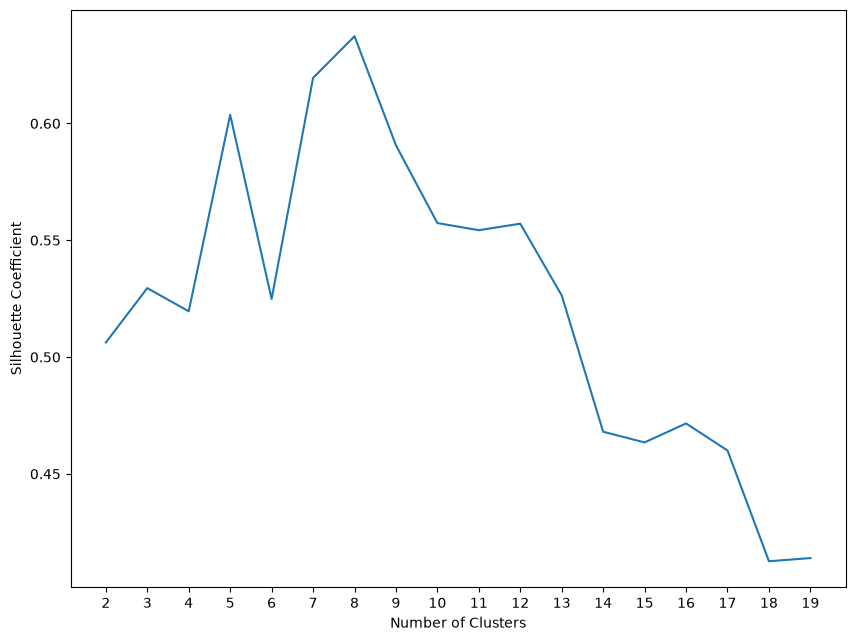

In [27]:
plt.plot(range(2, 20), silhouette_coefficients)
plt.xticks(range(2, 20))
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Coefficient")
plt.show()

Ultimately, your decision on the number of clusters to use should be guided by a combination of domain knowledge and clustering evaluation metrics.

# Some other examples of built in functions and clustering alghoritms. 

## Hierarchical Clustering

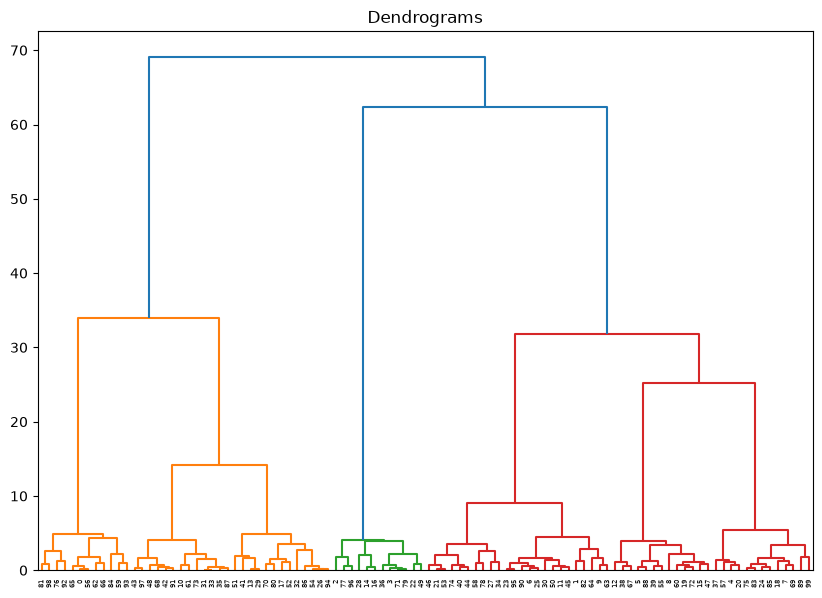

In [28]:
import scipy.cluster.hierarchy as shc
plt.figure(figsize=(10, 7))  
plt.title("Dendrograms")  
dend = shc.dendrogram(shc.linkage(X, method='ward'))
plt.show()

The x-axis represents our data points and y-axis - the Euclidean distance between the clusters. How to determine the optimal number of clusters from this diagram? Just visually, we can look for the largest distance (y axis) that we can vertically, without crossing any horizontal line (before splitting). The longer is the distance, the more clusters differ from each other. 
In this example, we can imagine a horizontal line above ~15. Since the distances between the corresponding clusters are rather small, we can safely draw a line at position 20 to determine the optimal number of clusters. In our case, the optimal number of clusters is between 4. This also corresponds to the elbow method, but differs from silouette coefficient method. 

In [29]:
# Fitting hierarchical clustering to the dataset
# There are two algorithms for hierarchical clustering: Agglomerative Hierarchical Clustering and 
# Divisive Hierarchical Clustering. We choose Euclidean distance and ward method for our algorithm class

from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

In [30]:
y_hc

array([3, 4, 2, 2, 0, 0, 4, 0, 0, 4, 1, 4, 0, 1, 2, 0, 2, 1, 0, 0, 0, 4,
       2, 4, 0, 4, 1, 4, 2, 1, 4, 1, 1, 1, 4, 1, 2, 0, 0, 0, 4, 1, 1, 1,
       4, 4, 4, 0, 1, 2, 4, 1, 1, 4, 1, 0, 3, 0, 4, 3, 0, 1, 3, 4, 4, 3,
       3, 0, 1, 0, 1, 2, 0, 1, 4, 0, 3, 2, 4, 2, 1, 3, 4, 0, 3, 0, 1, 1,
       0, 0, 4, 1, 3, 3, 1, 4, 2, 1, 3, 0])

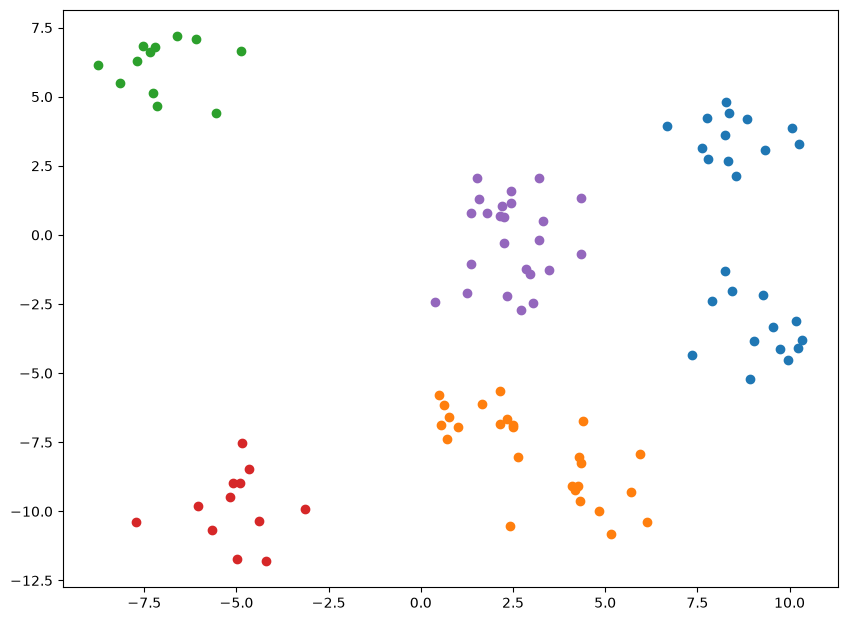

In [31]:
for i in range(5):
    plt.scatter(X[y_hc == i,0],X[y_hc == i,1])

plt.show()

## DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

Perform DBSCAN clustering from vector array or distance matrix.

DBSCAN - Density-Based Spatial Clustering of Applications with Noise. Finds core samples of high density and expands clusters from them. Good for data which contains clusters of similar density (https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html).


(-12.0, 12.0)

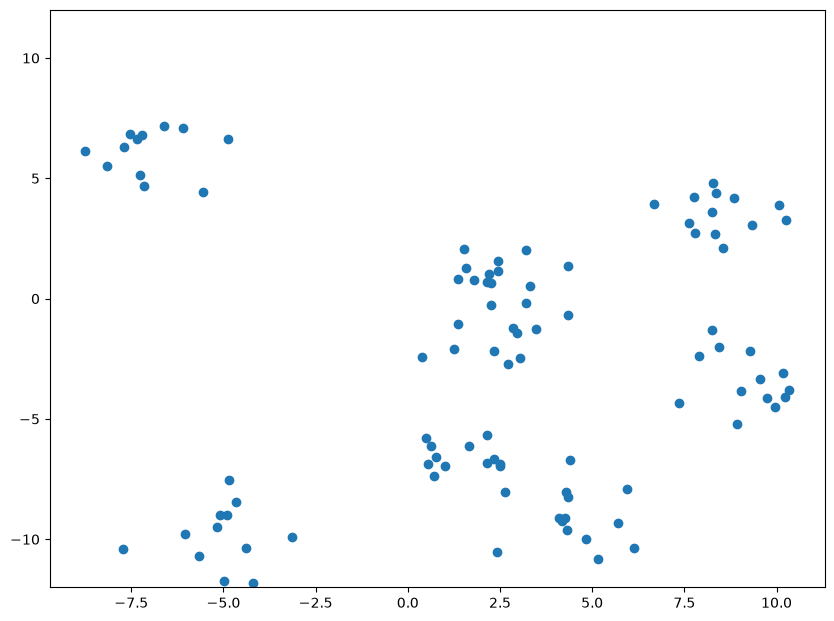

In [32]:
# Let's first display again our original data
plt.scatter(X[:, 0], X[:, 1])
# setting y-axis limits for better evaluation of the distance between the points
plt.ylim((-12,12))

We will construct a DBSCAN object that requires a minimum of 4 data points in a neighborhood of radius 2.5 to be considered a core point.

In [33]:
from sklearn.cluster import DBSCAN
# define the model
model = DBSCAN(eps=2, min_samples=3)
# fit model and predict clusters
yhat = model.fit_predict(X)
# retrieve unique clusters
clusters = np.unique(yhat)
clusters

array([-1,  0,  1,  2,  3,  4,  5])

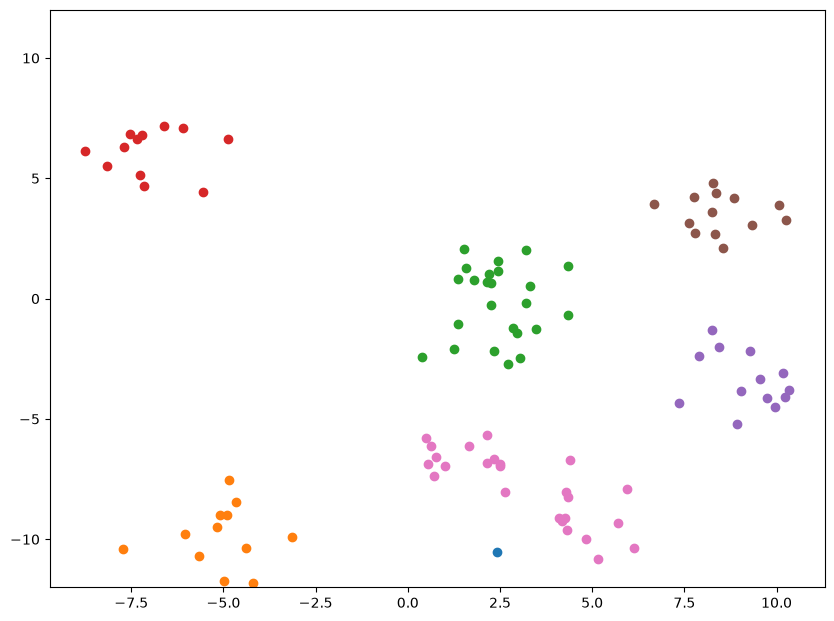

In [34]:
# create scatter plot for samples from each cluster
for cluster in clusters:
    # get row indexes for samples with this cluster
    row_ix = np.where(yhat == cluster)
    # create scatter of these samples
    plt.scatter(X[row_ix, 0], X[row_ix, 1])
    plt.ylim((-12,12))
    
# show the plot
plt.show()

# Principal Component Analysis (PCA)

PCA is a dimensionality reduction technique that transforms high-dimensional data into a lower-dimensional space while preserving as much variance as possible. It's useful for:
* Visualizing high-dimensional data
* Reducing computational complexity
* Removing noise and redundant features
* Data compression

PCA works by finding the principal components (directions of maximum variance) in the data.

## Example 1: PCA on the Iris Dataset

Let's start with a classic example using the Iris dataset, which has 4 features. We'll reduce it to 2 dimensions for visualization.

In [35]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load the Iris dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

print(f"Original shape: {X_iris.shape}")
print(f"Features: {iris.feature_names}")

Original shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [36]:
X_iris[0:5]

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2]])

Standardize the features before applying PCA (important when features have different scales):

In [37]:
# Standardize the features
scaler = StandardScaler()
X_iris_scaled = scaler.fit_transform(X_iris)

In [38]:
X_iris_scaled[0:5]

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

In [39]:


# Apply PCA to reduce to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_iris_scaled)

print(f"Shape after PCA: {X_pca.shape}")
print(f"\nExplained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")

Shape after PCA: (150, 2)

Explained variance ratio: [0.72962445 0.22850762]
Total variance explained: 95.81%


In [40]:
X_pca

array([[-2.26470281,  0.4800266 ],
       [-2.08096115, -0.67413356],
       [-2.36422905, -0.34190802],
       [-2.29938422, -0.59739451],
       [-2.38984217,  0.64683538],
       [-2.07563095,  1.48917752],
       [-2.44402884,  0.0476442 ],
       [-2.23284716,  0.22314807],
       [-2.33464048, -1.11532768],
       [-2.18432817, -0.46901356],
       [-2.1663101 ,  1.04369065],
       [-2.32613087,  0.13307834],
       [-2.2184509 , -0.72867617],
       [-2.6331007 , -0.96150673],
       [-2.1987406 ,  1.86005711],
       [-2.26221453,  2.68628449],
       [-2.2075877 ,  1.48360936],
       [-2.19034951,  0.48883832],
       [-1.898572  ,  1.40501879],
       [-2.34336905,  1.12784938],
       [-1.914323  ,  0.40885571],
       [-2.20701284,  0.92412143],
       [-2.7743447 ,  0.45834367],
       [-1.81866953,  0.08555853],
       [-2.22716331,  0.13725446],
       [-1.95184633, -0.62561859],
       [-2.05115137,  0.24216355],
       [-2.16857717,  0.52714953],
       [-2.13956345,

Visualize the data in 2D PCA space:

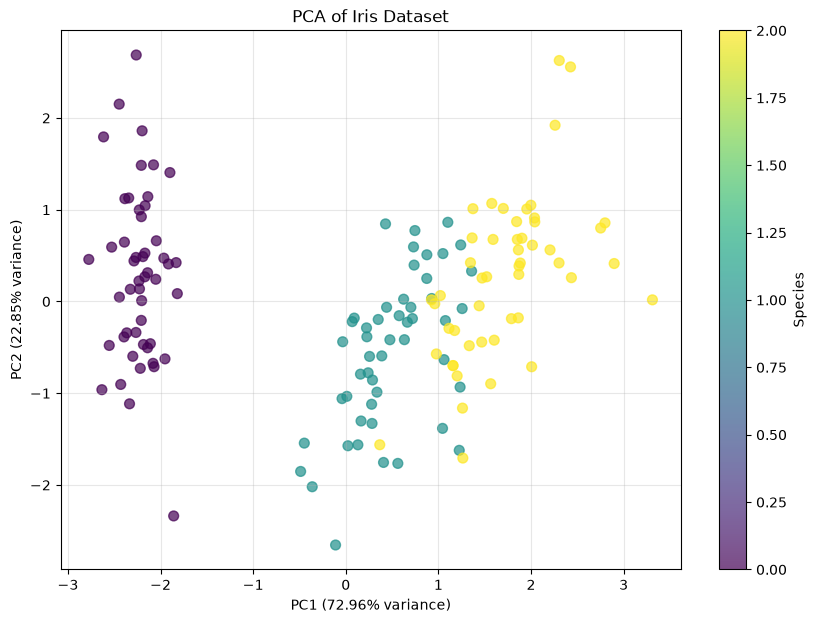

In [41]:
# Create a scatter plot
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_iris, cmap='viridis', s=50, alpha=0.7)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.title('PCA of Iris Dataset')
plt.colorbar(scatter, label='Species')
plt.grid(True, alpha=0.3)
plt.show()

The PCA plot of the Iris dataset shows how the 4-dimensional flower measurements are transformed into a 2-dimensional space. Here's what each element means:

Axes:

PC1 (X-axis): The first principal component - the direction in the original 4D space that captures the maximum variance in the data. The percentage shows how much of the total variance this component explains (typically ~73%).
PC2 (Y-axis): The second principal component - the direction orthogonal (perpendicular) to PC1 that captures the second-most variance (typically ~23%).
Colors: Each color represents one of the three Iris species:<br>

Setosa (one cluster)<br>
Versicolor (middle cluster)<br>
Virginica (another cluster)<br>
What it reveals:

Dimensionality Reduction: The original 4 features (sepal length, sepal width, petal length, petal width) are compressed into just 2 dimensions while retaining ~95% of the variance.

Species Separation: The plot clearly shows that:

One species (typically Setosa) is very distinct and well-separated
The other two species (Versicolor and Virginica) have some overlap but are mostly distinguishable
Clustering Structure: Even without knowing the species labels, you can visually identify 3 distinct groups, which validates that clustering algorithms would work well on this data.

## Determining the Optimal Number of Components

Use the explained variance to decide how many components to keep:

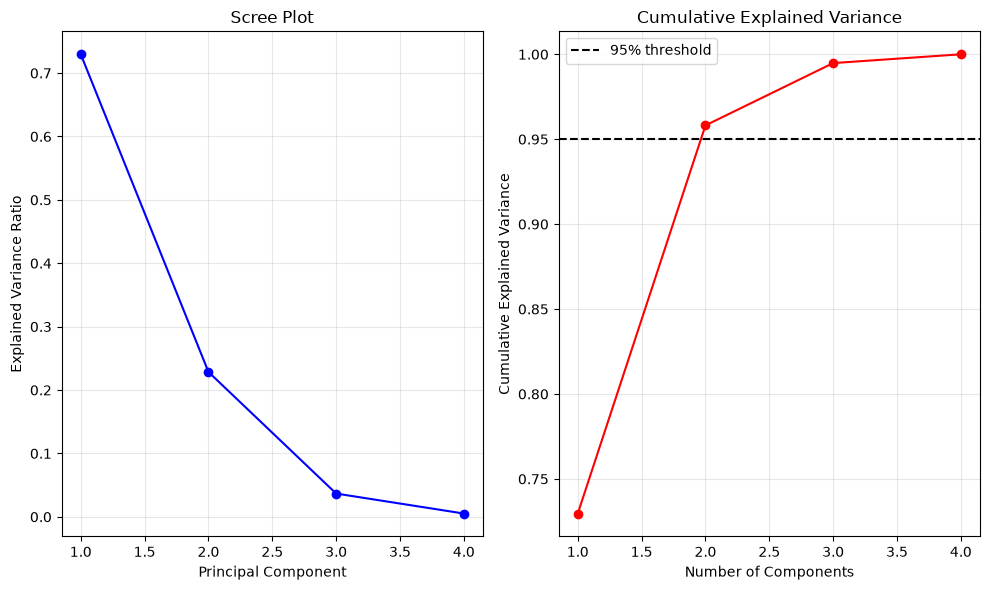

Explained variance by each component:
PC1: 72.96%
PC2: 22.85%
PC3: 3.67%
PC4: 0.52%


In [42]:
# Apply PCA with all components
pca_full = PCA()
pca_full.fit(X_iris_scaled)

# Plot cumulative explained variance
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1), 
         pca_full.explained_variance_ratio_, 'bo-')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
         np.cumsum(pca_full.explained_variance_ratio_), 'ro-')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.axhline(y=0.95, color='k', linestyle='--', label='95% threshold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Explained variance by each component:")
for i, var in enumerate(pca_full.explained_variance_ratio_):
    print(f"PC{i+1}: {var:.2%}")

## Visualizing Principal Components

Let's examine what the principal components actually represent:

Component loadings (feature contributions to PCs):
                        PC1       PC2
sepal length (cm)  0.521066  0.377418
sepal width (cm)  -0.269347  0.923296
petal length (cm)  0.580413  0.024492
petal width (cm)   0.564857  0.066942


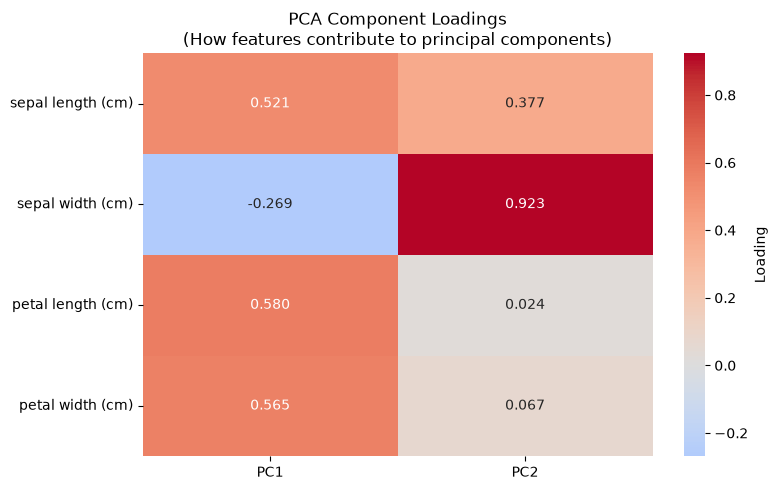

In [43]:
# Component loadings (how much each original feature contributes to each PC)
components_df = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=iris.feature_names
)

print("Component loadings (feature contributions to PCs):")
print(components_df)

# Visualize as heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(components_df, annot=True, cmap='coolwarm', center=0, 
            cbar_kws={'label': 'Loading'}, fmt='.3f')
plt.title('PCA Component Loadings\n(How features contribute to principal components)')
plt.tight_layout()
plt.show()

### Using PCA with a Classifier to Predict Species

You can use PCA to reduce dimensionality, then train a classifier (e.g., Logistic Regression) on the PCA-transformed data. Here is an example:

In [44]:
species_names = iris.target_names
species_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

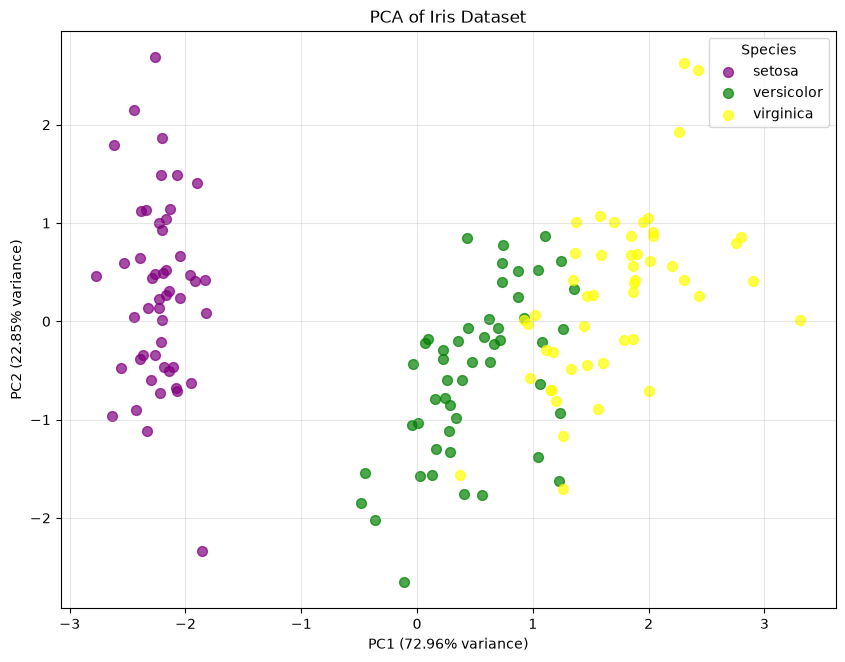

In [45]:

colors = ['purple', 'green', 'yellow']
for i, name in enumerate(species_names):
    plt.scatter(X_pca[y_iris == i, 0], X_pca[y_iris == i, 1], 
                label=name, color=colors[i], s=50, alpha=0.7)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.title('PCA of Iris Dataset')
plt.legend(title='Species')
plt.grid(True, alpha=0.3)
plt.show()

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Use the PCA-transformed data (X_pca) and true labels (y_iris)
X_train, X_test, y_train, y_test = train_test_split(X_pca, y_iris, test_size=0.3, random_state=101)

# Train a classifier on the PCA data
clf = LogisticRegression(max_iter=200)
clf.fit(X_train, y_train)

# Predict on the test set
y_pred = clf.predict(X_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9111111111111111
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       1.00      0.80      0.89        20
   virginica       0.75      1.00      0.86        12

    accuracy                           0.91        45
   macro avg       0.92      0.93      0.92        45
weighted avg       0.93      0.91      0.91        45



In [47]:
# Use the original data (X_iris) and true labels (y_iris)
X_train, X_test, y_train, y_test = train_test_split(X_iris, y_iris, test_size=0.3, random_state=101)

# Train a classifier on the original data
clf = LogisticRegression(max_iter=200)
clf.fit(X_train, y_train)

# Predict on the test set
y_pred = clf.predict(X_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9777777777777777
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       1.00      0.95      0.97        20
   virginica       0.92      1.00      0.96        12

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45

